In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import nltk
from nltk.corpus import stopwords
from nltk import ngrams
from wordcloud import WordCloud

In [3]:
# 1) Setup & load data
nltk.download('punkt')
nltk.download('stopwords')
STOPWORDS = set(stopwords.words('english'))

# replace with your actual path/filename
df = pd.read_csv("/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/leo_summary_cleaned.csv")  

# assume your text column is named 'post'
TEXT_COL = "Summary"

# auto-detect binary category columns (values subset {0,1})
cat_cols = [
    c for c in df.columns 
    if c != TEXT_COL 
    and set(df[c].dropna().unique()).issubset({0,1})
]

[nltk_data] Downloading package punkt to /Users/emine2/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/emine2/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## EDA: we need to get a sense of both the labels and the text. 
1. Dataset overview: shape, number of missing values, sample texts
2. Label (category) analysis: 
- which categories exist and how many posts carry each one?
- How many labels per post (label count distribution)?
- correlations / co-occurence between categories
3. text lenght analysis: distribution of character counts and workd counts
4. term-frequency analysis: Top unigrams $ bigrams (after stopword removal) and word clouds o visually inspect dominant terms


### 1. Set-up and load data

In [4]:
# 2) Overview
print("Dataset shape:", df.shape)
print("Missing values per column:\n", df.isna().sum())
print("Sample posts:")
display(df[[TEXT_COL] + cat_cols].head())

Dataset shape: (3568, 105)
Missing values per column:
 Summary       79
WEATHER        0
OCEAN          0
LAND           0
SAFETY         0
              ..
ANISAKID       0
QFEVER         0
GIARDIASIS     0
DIPHTHERIA     0
MONKEYPOX      0
Length: 105, dtype: int64
Sample posts:


,Summary,WEATHER,OCEAN,LAND,SAFETY,WATER,SNOW,HEALTH,TRANSPORTATION,DIEOFF,...,TRICHINOSIS,BOTULISM,ALASKAPOX,BRUCELLOSIS,CORONAVIRUS,ANISAKID,QFEVER,GIARDIASIS,DIPHTHERIA,MONKEYPOX
0,"On the last Sunday in April, I received a brie...",0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,The Alaska Migratory Bird Co-Management Counci...,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,"We have a lot of phenological events, but how ...",0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Localized erosion from the spring melt has led...,0,0,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,"Ned Rozell’s article explores the vast, geolog...",0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### 2. Label analysis

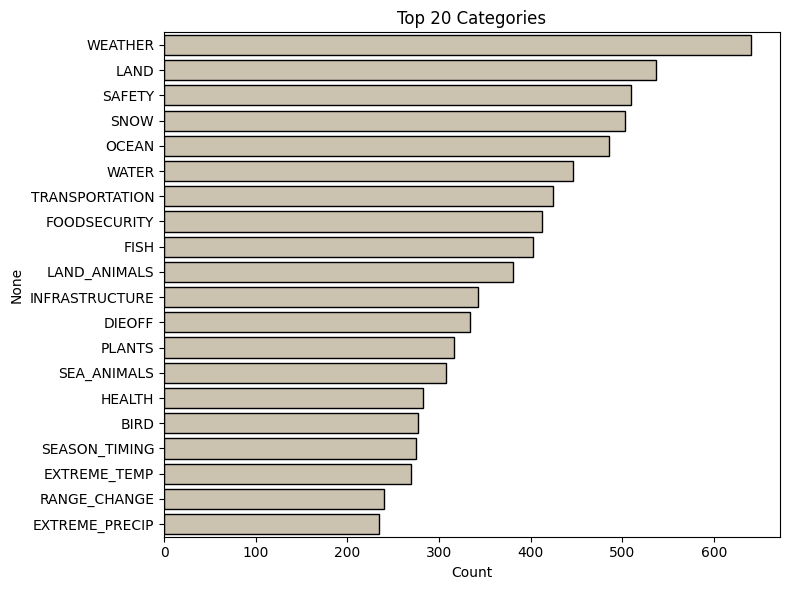

In [5]:
# 3) Label distribution
label_counts = df[cat_cols].sum().sort_values(ascending=False)
# Plot top 10 categories
top10 = label_counts.head(20)
plt.figure(figsize=(8,6))
sns.barplot(x=top10.values, y=top10.index, color='#CFC3AC', edgecolor='black')
plt.title("Top 20 Categories")
plt.xlabel("Count")
plt.tight_layout()
plt.show()

### 2.1. Label correlation heatmap

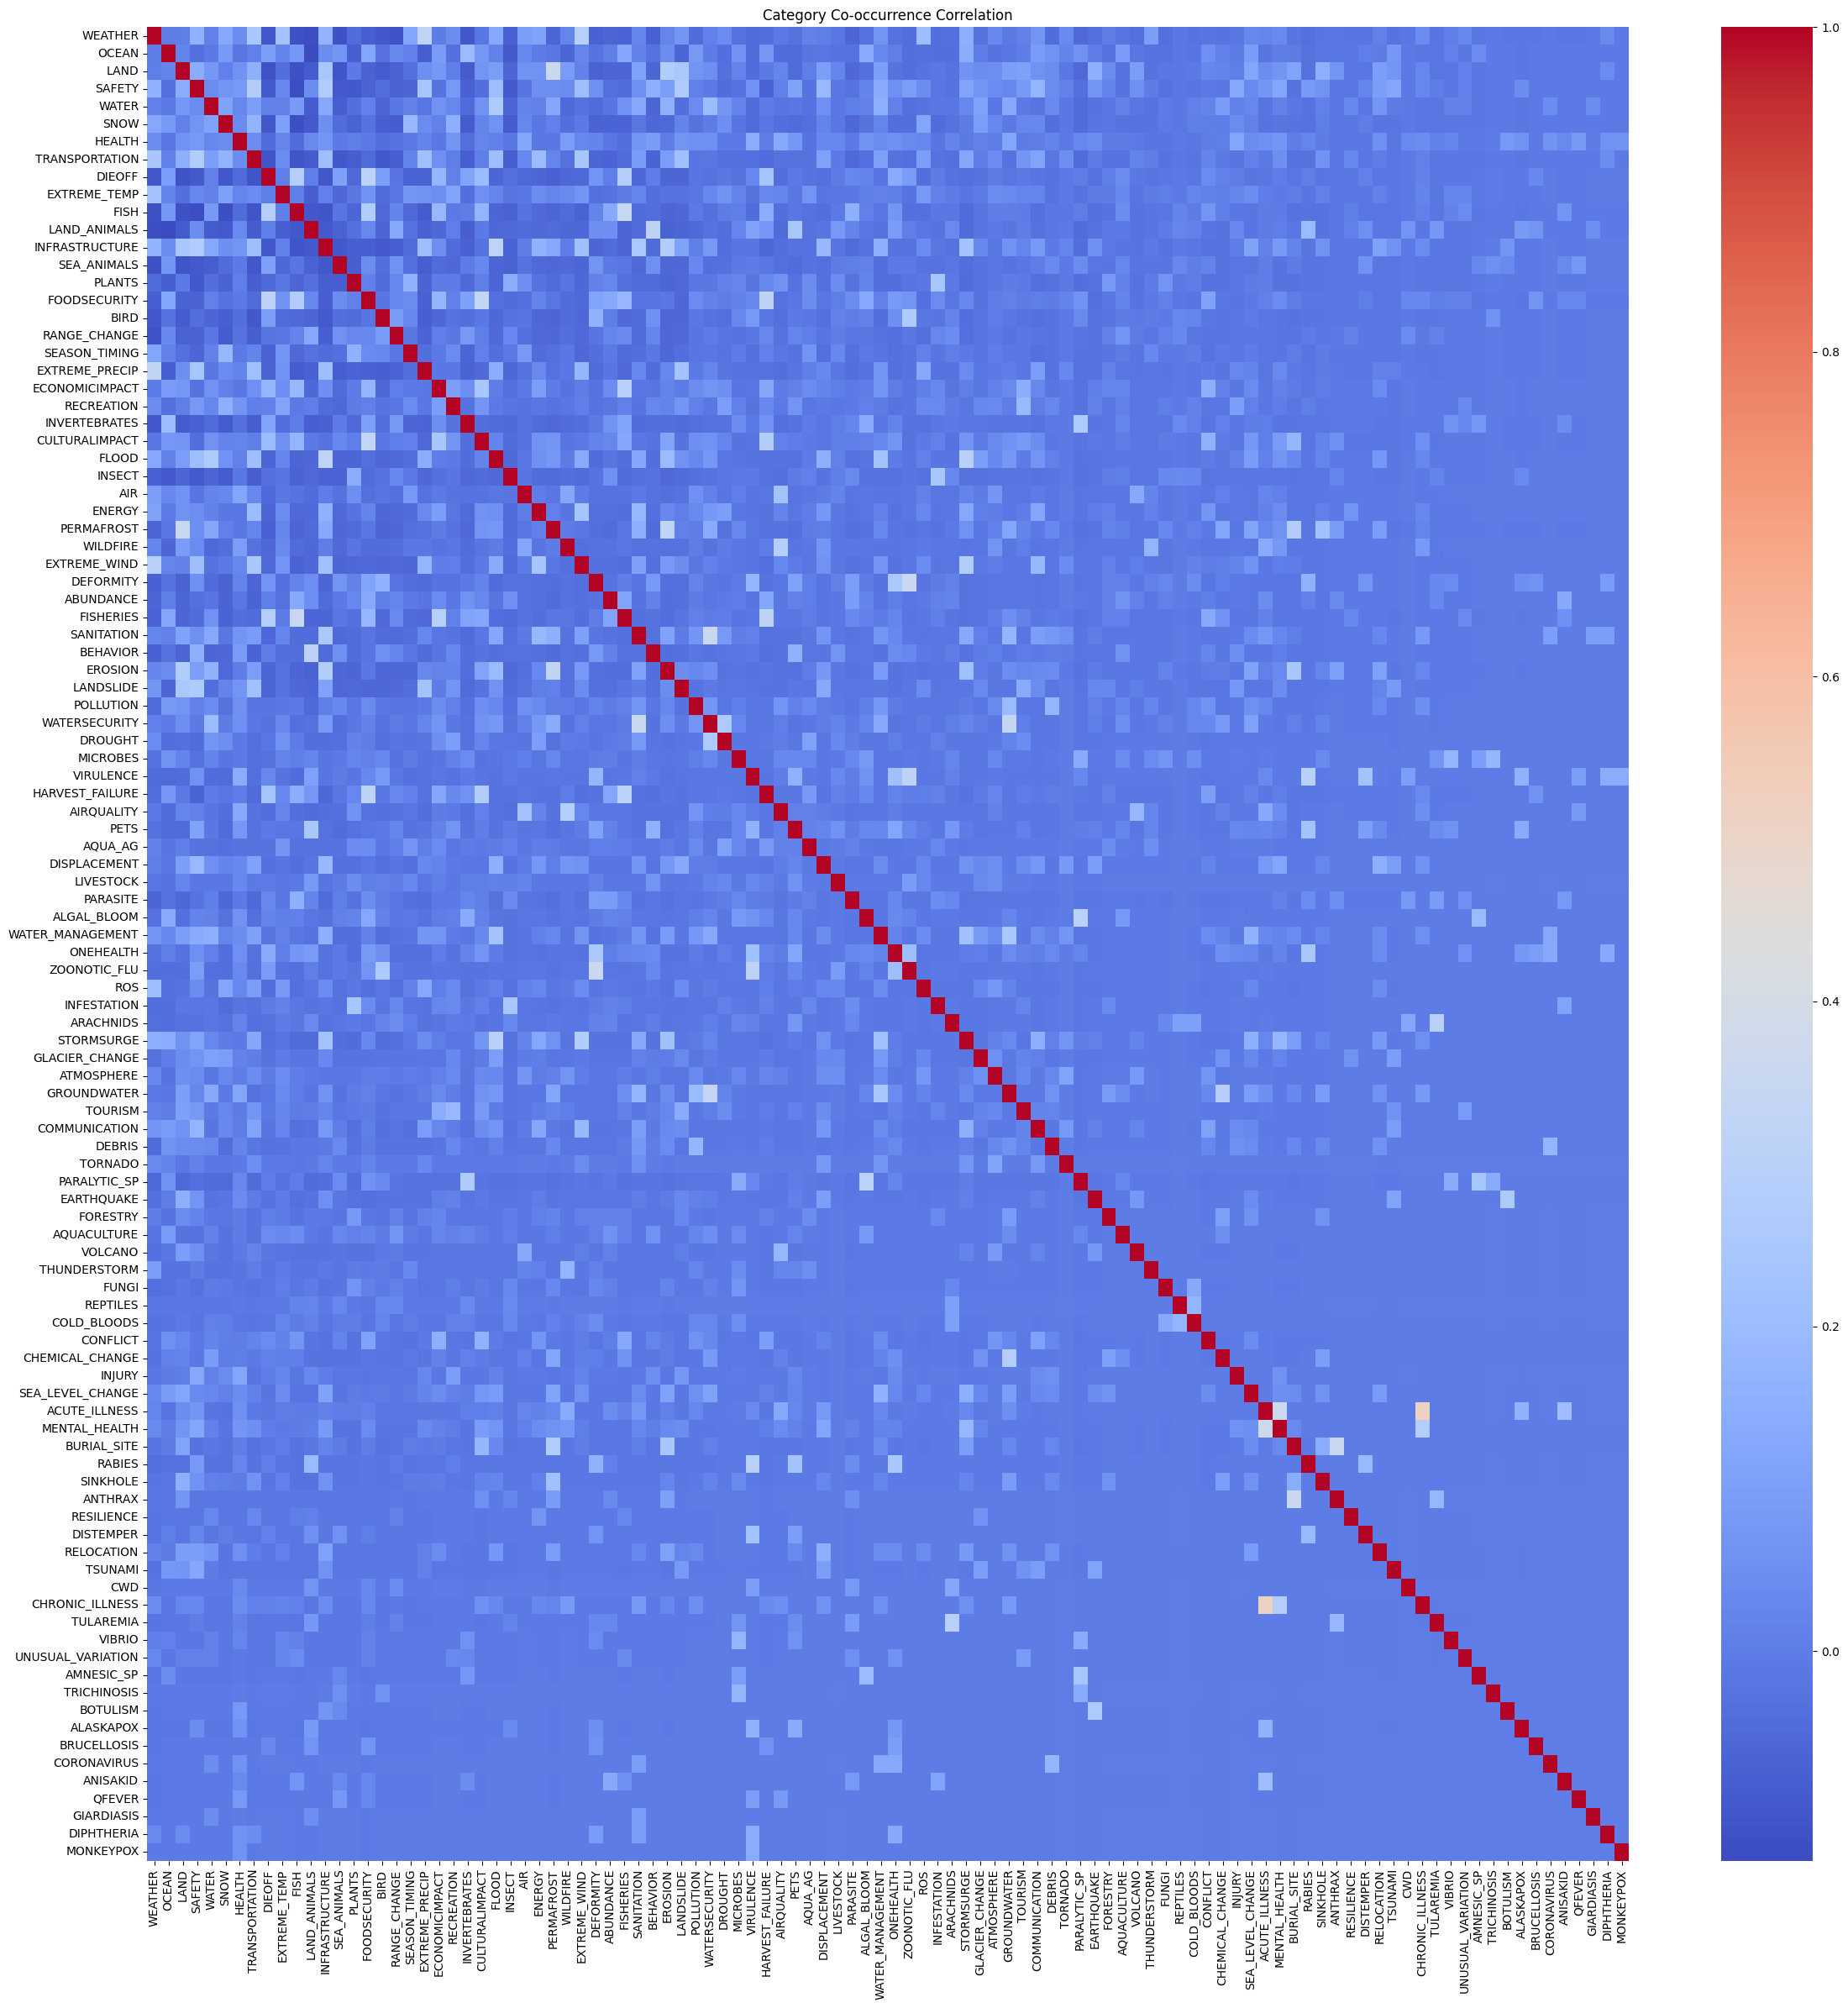

In [6]:
# 4) Label correlation heatmap
plt.figure(figsize=(24,24))
sns.heatmap(df[cat_cols].corr(),  fmt=".2f", cmap="coolwarm")
plt.title("Category Co‐occurrence Correlation")
plt.tight_layout()
plt.show()


### 3. text length distributions

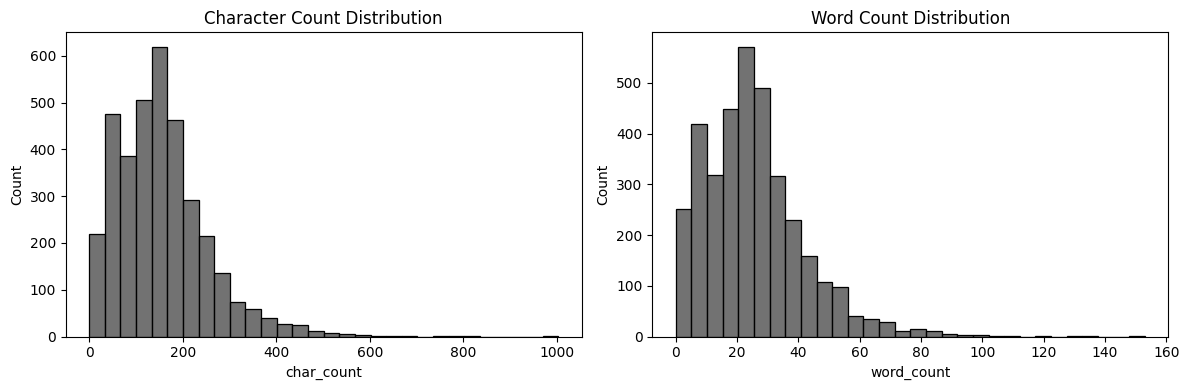

In [7]:
# 5) Text length distributions
df['clean_post'] = df[TEXT_COL].fillna("")

# now length in chars and words
df['char_count'] = df['clean_post'].str.len()
df['word_count'] = df['clean_post'].str.split().apply(len)

fig, axes = plt.subplots(1,2, figsize=(12,4))
sns.histplot(df['char_count'], bins=30, ax=axes[0], color='#434343', edgecolor='black')
axes[0].set_title("Character Count Distribution")
sns.histplot(df['word_count'], bins=30, ax=axes[1], color='#434343', edgecolor='black')
axes[1].set_title("Word Count Distribution")
plt.tight_layout()
plt.show()

### 4. Tokenize and remove stop words

In [8]:
BASE_STOPWORDS = set(stopwords.words('english'))
EXTRA_STOPWORDS = {'alaska', 'usa'}             # ← add whatever else you want to strip
ALL_STOPWORDS = BASE_STOPWORDS.union(EXTRA_STOPWORDS)


In [9]:
# Tokenizer that strips stopwords + non-alpha
def tokenize(text):
    tokens = nltk.word_tokenize(text.lower())
    return [t for t in tokens 
            if t.isalpha() 
            and t not in ALL_STOPWORDS]
df['tokens'] = df[TEXT_COL].fillna("").apply(tokenize)


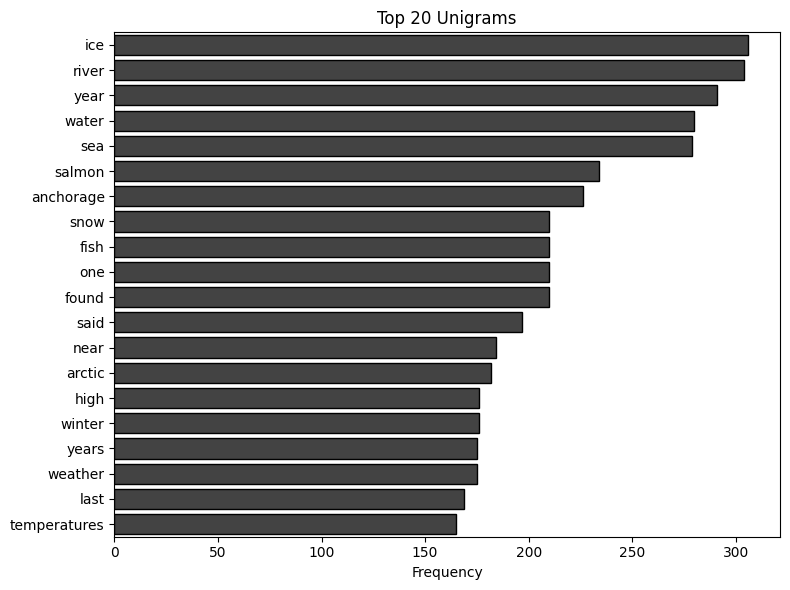

In [10]:
# 7) Top unigrams
all_unigrams = Counter([w for tokens in df['tokens'] for w in tokens])
top_unigrams = all_unigrams.most_common(20)
words, counts = zip(*top_unigrams)
plt.figure(figsize=(8,6))
sns.barplot(x=list(counts), y=list(words), color='#434343', edgecolor='black')
plt.title("Top 20 Unigrams")
plt.xlabel("Frequency")
plt.tight_layout()
plt.show()

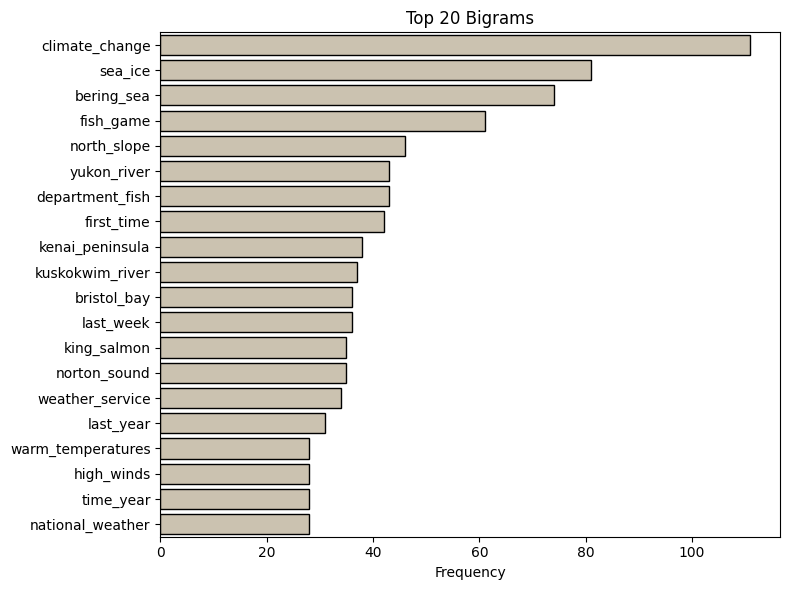

In [11]:
all_bigrams = Counter()
for tokens in df['tokens']:
    all_bigrams.update(ngrams(tokens, 2))
top_bigrams = all_bigrams.most_common(20)
bigrams, bcounts = zip(*top_bigrams)
bigram_labels = ["_".join(b) for b in bigrams]
plt.figure(figsize=(8,6))
sns.barplot(x=list(bcounts), y=bigram_labels, color='#CFC3AC', edgecolor='black')
plt.title("Top 20 Bigrams")
plt.xlabel("Frequency")
plt.tight_layout()
plt.show()

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
vect = TfidfVectorizer(max_df=0.9, min_df=5, stop_words='english', ngram_range=(1,1))
X_tfidf = vect.fit_transform(df[TEXT_COL].fillna(""))
top_tfidf = np.argsort(np.asarray(X_tfidf.sum(axis=0)).ravel())[::-1][:20]
feature_names = np.array(vect.get_feature_names_out())
print("Top 20 TF-IDF features:")
print(feature_names[top_tfidf])

Top 20 TF-IDF features:
['alaska' 'river' 'ice' 'year' 'sea' 'water' 'salmon' 'usa' 'anchorage'
 'snow' 'fish' 'early' 'near' 'arctic' 'weather' 'dead' 'winter' 'seen'
 'high' 'unusual']


## 1. Multimodal Naive Bayes



In [13]:
BASE_STOPWORDS = set(stopwords.words('english'))
EXTRA_STOPWORDS = {'alaska', 'usa'}             # ← add whatever else you want to strip
ALL_STOPWORDS = BASE_STOPWORDS.union(EXTRA_STOPWORDS)

In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

In [15]:
cat_cols


['WEATHER',
 'OCEAN',
 'LAND',
 'SAFETY',
 'WATER',
 'SNOW',
 'HEALTH',
 'TRANSPORTATION',
 'DIEOFF',
 'EXTREME_TEMP',
 'FISH',
 'LAND_ANIMALS',
 'INFRASTRUCTURE',
 'SEA_ANIMALS',
 'PLANTS',
 'FOODSECURITY',
 'BIRD',
 'RANGE_CHANGE',
 'SEASON_TIMING',
 'EXTREME_PRECIP',
 'ECONOMICIMPACT',
 'RECREATION',
 'INVERTEBRATES',
 'CULTURALIMPACT',
 'FLOOD',
 'INSECT',
 'AIR',
 'ENERGY',
 'PERMAFROST',
 'WILDFIRE',
 'EXTREME_WIND',
 'DEFORMITY',
 'ABUNDANCE',
 'FISHERIES',
 'SANITATION',
 'BEHAVIOR',
 'EROSION',
 'LANDSLIDE',
 'POLLUTION',
 'WATERSECURITY',
 'DROUGHT',
 'MICROBES',
 'VIRULENCE',
 'HARVEST_FAILURE',
 'AIRQUALITY',
 'PETS',
 'AQUA_AG',
 'DISPLACEMENT',
 'LIVESTOCK',
 'PARASITE',
 'ALGAL_BLOOM',
 'WATER_MANAGEMENT',
 'ONEHEALTH',
 'ZOONOTIC_FLU',
 'ROS',
 'INFESTATION',
 'ARACHNIDS',
 'STORMSURGE',
 'GLACIER_CHANGE',
 'ATMOSPHERE',
 'GROUNDWATER',
 'TOURISM',
 'COMMUNICATION',
 'DEBRIS',
 'TORNADO',
 'PARALYTIC_SP',
 'EARTHQUAKE',
 'FORESTRY',
 'AQUACULTURE',
 'VOLCANO',
 'THUNDER

In [16]:
X = df[TEXT_COL].fillna("") 
y = df[cat_cols]               # your binary-indicator columns


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


In [18]:
# ----  Multinomial Naive Bayes baseline ----
pipe_nb = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_df=0.9,
        min_df=5,
        ngram_range=(1,2),
        stop_words=list(ALL_STOPWORDS)   # ← use your combined set here
    )),
    ("clf", OneVsRestClassifier(MultinomialNB(), n_jobs=-1)),
])

pipe_nb.fit(X_train, y_train)
y_pred_nb = pipe_nb.predict(X_test)
print("=== Naive Bayes baseline ===")
from sklearn.metrics import classification_report

# assuming cat_cols is your list of column names in the same order y.columns
print(classification_report(
    y_test, 
    y_pred_nb,
    target_names=cat_cols,      # <-- this replaces 0,1,2... with your category names
    zero_division=0
))



=== Naive Bayes baseline ===
                   precision    recall  f1-score   support

          WEATHER       0.74      0.31      0.44       124
            OCEAN       0.50      0.07      0.12        85
             LAND       0.96      0.24      0.39        99
           SAFETY       0.75      0.09      0.16       104
            WATER       1.00      0.06      0.12        94
             SNOW       0.67      0.08      0.14       100
           HEALTH       0.00      0.00      0.00        49
   TRANSPORTATION       1.00      0.08      0.14        91
           DIEOFF       0.00      0.00      0.00        58
     EXTREME_TEMP       0.00      0.00      0.00        51
             FISH       1.00      0.18      0.31        82
     LAND_ANIMALS       1.00      0.17      0.29        65
   INFRASTRUCTURE       1.00      0.04      0.08        68
      SEA_ANIMALS       1.00      0.23      0.37        53
           PLANTS       1.00      0.12      0.21        67
     FOODSECURITY       1.

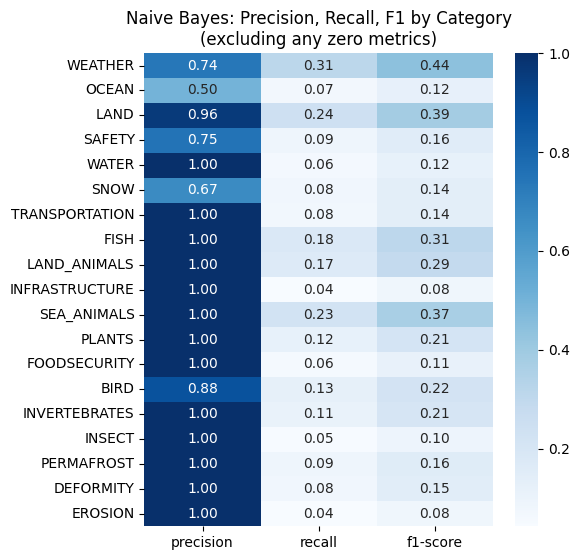

Categories with at least one zero in precision/recall/f1-score (omitted from plot):
- HEALTH
- DIEOFF
- EXTREME_TEMP
- RANGE_CHANGE
- SEASON_TIMING
- EXTREME_PRECIP
- ECONOMICIMPACT
- RECREATION
- CULTURALIMPACT
- FLOOD
- AIR
- ENERGY
- WILDFIRE
- EXTREME_WIND
- ABUNDANCE
- FISHERIES
- SANITATION
- BEHAVIOR
- LANDSLIDE
- POLLUTION
- WATERSECURITY
- DROUGHT
- MICROBES
- VIRULENCE
- HARVEST_FAILURE
- AIRQUALITY
- PETS
- AQUA_AG
- DISPLACEMENT
- LIVESTOCK
- PARASITE
- ALGAL_BLOOM
- WATER_MANAGEMENT
- ONEHEALTH
- ZOONOTIC_FLU
- ROS
- INFESTATION
- ARACHNIDS
- STORMSURGE
- GLACIER_CHANGE
- ATMOSPHERE
- GROUNDWATER
- TOURISM
- COMMUNICATION
- DEBRIS
- TORNADO
- PARALYTIC_SP
- EARTHQUAKE
- FORESTRY
- AQUACULTURE
- VOLCANO
- THUNDERSTORM
- FUNGI
- REPTILES
- COLD_BLOODS
- CONFLICT
- CHEMICAL_CHANGE
- INJURY
- SEA_LEVEL_CHANGE
- ACUTE_ILLNESS
- MENTAL_HEALTH
- BURIAL_SITE
- RABIES
- SINKHOLE
- ANTHRAX
- RESILIENCE
- DISTEMPER
- RELOCATION
- TSUNAMI
- CWD
- CHRONIC_ILLNESS
- TULAREMIA
- VIBRIO
-

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

# 1) Build the report as a dict for NB
report_nb = classification_report(
    y_test,
    y_pred_nb,
    target_names=cat_cols,
    output_dict=True,
    zero_division=0
)

# 2) To DataFrame and isolate categories
report_nb_df = pd.DataFrame(report_nb).transpose()
class_df_nb   = report_nb_df.loc[cat_cols]

# 3) Identify metrics and mask out any that have a zero
metrics = ["precision", "recall", "f1-score"]
mask_nonzero_all = (class_df_nb[metrics] > 0).all(axis=1)

nonzero_all_nb = class_df_nb[mask_nonzero_all]
zero_any_nb    = class_df_nb[~mask_nonzero_all].index.tolist()

# 4) Heatmap of precision/recall/F1 for non-zero categories
plt.figure(figsize=(6, len(nonzero_all_nb)*0.3))
sns.heatmap(
    nonzero_all_nb[metrics],
    annot=True,
    fmt=".2f",
    cmap="Blues"
)
plt.title("Naive Bayes: Precision, Recall, F1 by Category\n(excluding any zero metrics)")
plt.tight_layout()
plt.show()

# 5) Print omitted categories
print("Categories with at least one zero in precision/recall/f1-score (omitted from plot):")
for cat in zero_any_nb:
    print("-", cat)


In [20]:
y_test_df = pd.DataFrame(y_test, columns=cat_cols, index=X_test.index)
y_pred_df = pd.DataFrame(y_pred_nb, columns=cat_cols, index=X_test.index)

# 2) Boolean mask for “exact match” (all labels exactly correct)
mask_correct = (y_test_df.values == y_pred_df.values).all(axis=1)
mask_incorrect = ~mask_correct

# 3) Grab one example of each
idx_corr = X_test[mask_correct].index[12]
idx_inc  = X_test[mask_incorrect].index[12]

# 4) Function to list which categories are marked 1
def labels_of(row):
    return row[row==1].index.tolist()

# 5) Display them
print("=== Correctly Classified Example ===")
print("Text:", X_test.loc[idx_corr])
print("True labels:    ", labels_of(y_test_df.loc[idx_corr]))
print("Predicted labels:", labels_of(y_pred_df.loc[idx_corr]))
print("\n")

print("=== Misclassified Example ===")
print("Text:", X_test.loc[idx_inc])
print("True labels:    ", labels_of(y_test_df.loc[idx_inc]))
print("Predicted labels:", labels_of(y_pred_df.loc[idx_inc]))

=== Correctly Classified Example ===
Text: Early Ripe Blueberries (Vaccinium ovalifolium)
True labels:     ['PLANTS']
Predicted labels: ['PLANTS']


=== Misclassified Example ===
Text: Ocean acidification threatens some of Alaska’s most lucrative crab fisheries. But there’s one ray of hope: it’s possible that crabs might be able to adapt to the changing oceans. The big question scientists are researching at Bob Foy’s lab in Kodiak is – will they have enough time?
True labels:     ['OCEAN', 'INVERTEBRATES']
Predicted labels: ['OCEAN']


## 2. Logistic Regression with One - vs - Rest

In [21]:
# ---- Logistic Regression ----
pipe_lr = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_df=0.9, min_df=5, ngram_range=(1,2),
        stop_words='english'
    )),
    ("clf", OneVsRestClassifier(
        LogisticRegression(solver='liblinear'), 
        n_jobs=-1
    )),
])


# simple hyperparameter tuning example
param_grid = {
    "clf__estimator__C": [0.1, 1, 10]
}
grid_lr = GridSearchCV(
    pipe_lr, param_grid, cv=3, verbose=1, n_jobs=-1
)
grid_lr.fit(X_train, y_train)

print("Best C:", grid_lr.best_params_)
y_pred_lr = grid_lr.predict(X_test)
print("=== Logistic Regression (tuned) ===")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Fitting 3 folds for each of 3 candidates, totalling 9 fits


/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 98 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 101 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 88 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 94 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 103 is present in all training examples.
  warnings.warn(
/Us

Best C: {'clf__estimator__C': 10}
=== Logistic Regression (tuned) ===
              precision    recall  f1-score   support

           0       0.60      0.48      0.54       124
           1       0.44      0.26      0.33        85
           2       0.58      0.40      0.48        99
           3       0.65      0.36      0.46       104
           4       0.51      0.24      0.33        94
           5       0.62      0.40      0.49       100
           6       0.38      0.06      0.11        49
           7       0.62      0.31      0.41        91
           8       0.58      0.19      0.29        58
           9       0.40      0.12      0.18        51
          10       0.85      0.55      0.67        82
          11       0.76      0.40      0.53        65
          12       0.55      0.24      0.33        68
          13       0.90      0.53      0.67        53
          14       0.82      0.46      0.59        67
          15       0.43      0.16      0.23        82
          1

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Identify categories with **all** metrics > 0
metrics = ["precision", "recall", "f1-score"]
mask_nonzero_all = (class_df_lr[metrics] > 0).all(axis=1)

nonzero_all = class_df_lr[mask_nonzero_all]
zero_any    = class_df_lr[~mask_nonzero_all].index.tolist()

# 2) Heatmap for the ones with no zeros
plt.figure(figsize=(10, len(nonzero_all)*0.3))
sns.heatmap(
    nonzero_all[metrics],
    annot=True,
    fmt=".2f",
    cmap="Blues"
)
plt.title("Logistic Regression: Precision, Recall, F1 by Category\n(excluding any zero metrics)")
plt.tight_layout()
plt.show()

# 3) List out categories that had at least one zero
print("Categories with at least one zero in precision/recall/f1-score (omitted from plot):")
for cat in zero_any:
    print("-", cat)


NameError: name 'class_df_lr' is not defined

In [25]:
# 1) Build DataFrames for true vs. LR-predicted labels
y_test_df    = pd.DataFrame(y_test,    columns=cat_cols, index=X_test.index)
y_pred_lr_df = pd.DataFrame(y_pred_lr, columns=cat_cols, index=X_test.index)

# 2) Boolean masks for “exact match” vs. misclassified
mask_correct_lr   = (y_test_df.values == y_pred_lr_df.values).all(axis=1)
mask_incorrect_lr = ~mask_correct_lr

# 3) Pick one example of each (here using the first one in each set)
idx_corr_lr = X_test[mask_correct_lr].index[0]
idx_inc_lr  = X_test[mask_incorrect_lr].index[0]

# 4) Helper to list the active categories
def labels_of(row):
    return row[row == 1].index.tolist()

# 5) Display a correctly and an incorrectly classified post
print("=== Logistic Regression: Correctly Classified ===")
print("Text:           ", X_test.loc[idx_corr_lr])
print("True labels:    ", labels_of(y_test_df.loc[idx_corr_lr]))
print("Predicted labels:", labels_of(y_pred_lr_df.loc[idx_corr_lr]))
print()

print("=== Logistic Regression: Misclassified ===")
print("Text:           ", X_test.loc[idx_inc_lr])
print("True labels:    ", labels_of(y_test_df.loc[idx_inc_lr]))
print("Predicted labels:", labels_of(y_pred_lr_df.loc[idx_inc_lr]))


=== Logistic Regression: Correctly Classified ===
Text:            Ocean acidification threatens some of Alaska’s most lucrative crab fisheries. But there’s one ray of hope: it’s possible that crabs might be able to adapt to the changing oceans. The big question scientists are researching at Bob Foy’s lab in Kodiak is – will they have enough time?
True labels:     ['OCEAN', 'INVERTEBRATES']
Predicted labels: ['OCEAN', 'INVERTEBRATES']

=== Logistic Regression: Misclassified ===
Text:            The ride downriver had been good. But by evening on the way back, it started to get bumpy.“There was lots of dark spots, lots of water,” said Nikiefer. Then suddenly, the ice turned needley. The snowmachine stopped, and then started to sink. They jumped off and started to swim.
True labels:     ['SAFETY', 'WATER', 'SNOW', 'HEALTH', 'INJURY']
Predicted labels: ['WATER']


## 3. Random Forest

In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

# -- Baseline Random Forest pipeline --
pipe_rf = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_df=0.9,
        min_df=5,
        ngram_range=(1,2),
        stop_words=list(ALL_STOPWORDS)   # or 'english' if you prefer
    )),
    ("clf", OneVsRestClassifier(
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ),
        n_jobs=-1
    )),
])

# fit & predict
pipe_rf.fit(X_train, y_train)
y_pred_rf = pipe_rf.predict(X_test)

print("=== Random Forest baseline ===")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=cat_cols,
    zero_division=0
))


# -- Optional: hyperparameter tuning --
param_grid_rf = {
    "clf__estimator__n_estimators": [100, 200],
    "clf__estimator__max_depth": [None, 20, 50],
    # you can add more params here (min_samples_leaf, etc.)
}

grid_rf = GridSearchCV(
    pipe_rf,
    param_grid_rf,
    cv=3,
    n_jobs=-1,
    verbose=1
)
grid_rf.fit(X_train, y_train)

print("Best RF params:", grid_rf.best_params_)
y_pred_rf_tuned = grid_rf.predict(X_test)

print("=== Random Forest (tuned) ===")
print(classification_report(
    y_test,
    y_pred_rf_tuned,
    target_names=cat_cols,
    zero_division=0
))


=== Random Forest baseline ===
                   precision    recall  f1-score   support

          WEATHER       0.64      0.47      0.54       124
            OCEAN       0.53      0.24      0.33        85
             LAND       0.59      0.38      0.47        99
           SAFETY       0.80      0.12      0.20       104
            WATER       0.48      0.13      0.20        94
             SNOW       0.67      0.38      0.48       100
           HEALTH       0.50      0.02      0.04        49
   TRANSPORTATION       0.77      0.11      0.19        91
           DIEOFF       0.38      0.09      0.14        58
     EXTREME_TEMP       0.67      0.08      0.14        51
             FISH       0.82      0.55      0.66        82
     LAND_ANIMALS       0.91      0.45      0.60        65
   INFRASTRUCTURE       0.86      0.09      0.16        68
      SEA_ANIMALS       0.90      0.53      0.67        53
           PLANTS       0.83      0.51      0.63        67
     FOODSECURITY       

/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 88 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 94 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 103 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 98 is present in all training examples.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/multiclass.py:90: UserWarning: Label not 101 is present in all training examples.
  warnings.warn(
/Us

Best RF params: {'clf__estimator__max_depth': None, 'clf__estimator__n_estimators': 100}
=== Random Forest (tuned) ===
                   precision    recall  f1-score   support

          WEATHER       0.64      0.47      0.54       124
            OCEAN       0.53      0.24      0.33        85
             LAND       0.59      0.38      0.47        99
           SAFETY       0.80      0.12      0.20       104
            WATER       0.48      0.13      0.20        94
             SNOW       0.67      0.38      0.48       100
           HEALTH       0.50      0.02      0.04        49
   TRANSPORTATION       0.77      0.11      0.19        91
           DIEOFF       0.38      0.09      0.14        58
     EXTREME_TEMP       0.67      0.08      0.14        51
             FISH       0.82      0.55      0.66        82
     LAND_ANIMALS       0.91      0.45      0.60        65
   INFRASTRUCTURE       0.86      0.09      0.16        68
      SEA_ANIMALS       0.90      0.53      0.67      

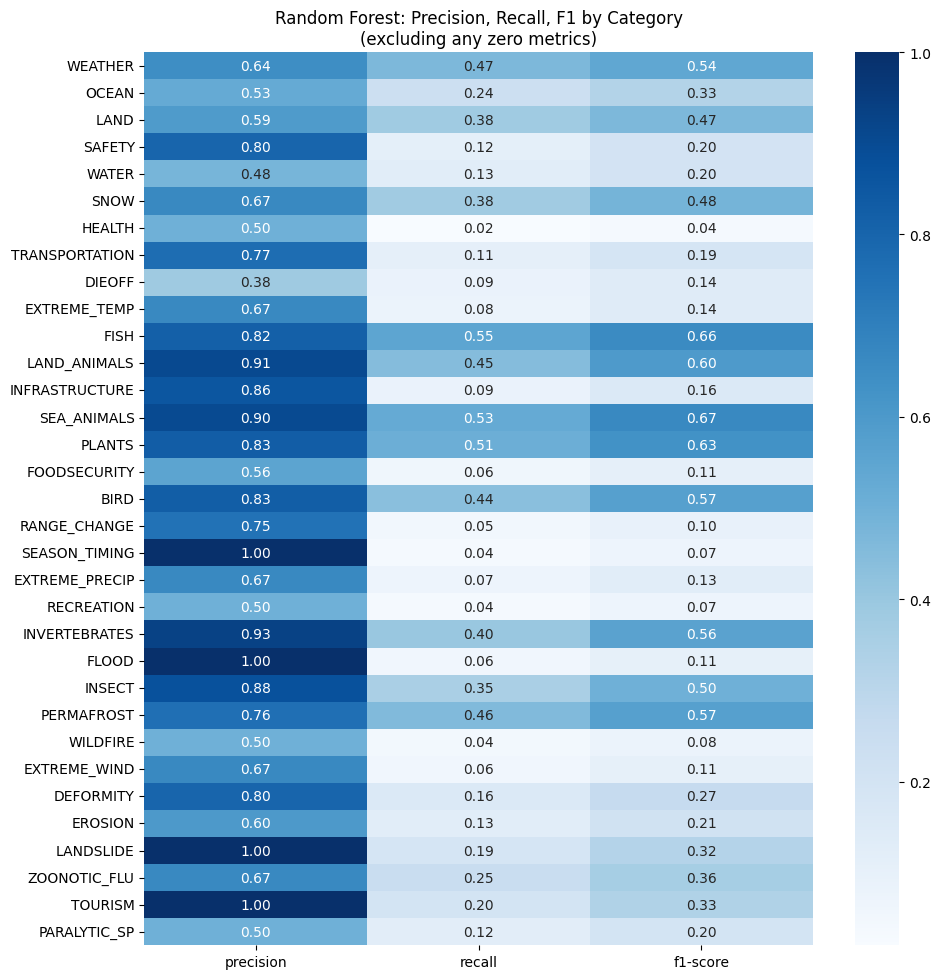

Categories with at least one zero in precision/recall/f1-score (omitted from plot):
- ECONOMICIMPACT
- CULTURALIMPACT
- AIR
- ENERGY
- ABUNDANCE
- FISHERIES
- SANITATION
- BEHAVIOR
- POLLUTION
- WATERSECURITY
- DROUGHT
- MICROBES
- VIRULENCE
- HARVEST_FAILURE
- AIRQUALITY
- PETS
- AQUA_AG
- DISPLACEMENT
- LIVESTOCK
- PARASITE
- ALGAL_BLOOM
- WATER_MANAGEMENT
- ONEHEALTH
- ROS
- INFESTATION
- ARACHNIDS
- STORMSURGE
- GLACIER_CHANGE
- ATMOSPHERE
- GROUNDWATER
- COMMUNICATION
- DEBRIS
- TORNADO
- EARTHQUAKE
- FORESTRY
- AQUACULTURE
- VOLCANO
- THUNDERSTORM
- FUNGI
- REPTILES
- COLD_BLOODS
- CONFLICT
- CHEMICAL_CHANGE
- INJURY
- SEA_LEVEL_CHANGE
- ACUTE_ILLNESS
- MENTAL_HEALTH
- BURIAL_SITE
- RABIES
- SINKHOLE
- ANTHRAX
- RESILIENCE
- DISTEMPER
- RELOCATION
- TSUNAMI
- CWD
- CHRONIC_ILLNESS
- TULAREMIA
- VIBRIO
- UNUSUAL_VARIATION
- AMNESIC_SP
- TRICHINOSIS
- BOTULISM
- ALASKAPOX
- BRUCELLOSIS
- CORONAVIRUS
- ANISAKID
- QFEVER
- GIARDIASIS
- DIPHTHERIA
- MONKEYPOX


In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

# 1) Build the report as a dict for Random Forest
report_rf = classification_report(
    y_test,
    y_pred_rf,              # or y_pred_rf_tuned if you want the tuned version
    target_names=cat_cols,
    output_dict=True,
    zero_division=0
)

# 2) To DataFrame and isolate just the category rows
report_rf_df = pd.DataFrame(report_rf).transpose()
class_df_rf  = report_rf_df.loc[cat_cols]

# 3) Identify the three metrics and mask out any category having a zero
metrics = ["precision", "recall", "f1-score"]
mask_nonzero_all = (class_df_rf[metrics] > 0).all(axis=1)

nonzero_all_rf = class_df_rf[mask_nonzero_all]
zero_any_rf    = class_df_rf[~mask_nonzero_all].index.tolist()

# 4) Heatmap of precision / recall / f1 for non-zero-only categories
plt.figure(figsize=(10, len(nonzero_all_rf) * 0.3))
sns.heatmap(
    nonzero_all_rf[metrics],
    annot=True,
    fmt=".2f",
    cmap="Blues"
)
plt.title("Random Forest: Precision, Recall, F1 by Category\n(excluding any zero metrics)")
plt.tight_layout()
plt.show()

# 5) Print the omitted categories
print("Categories with at least one zero in precision/recall/f1-score (omitted from plot):")
for cat in zero_any_rf:
    print("-", cat)


In [56]:
# 1) Build DataFrames for true vs. RF‐predicted labels
y_test_df     = pd.DataFrame(y_test,     columns=cat_cols, index=X_test.index)
y_pred_rf_df  = pd.DataFrame(y_pred_rf,  columns=cat_cols, index=X_test.index)
# If you want the tuned RF instead, replace y_pred_rf with y_pred_rf_tuned above

# 2) Boolean masks for “exact match” vs. misclassified
mask_correct_rf   = (y_test_df.values == y_pred_rf_df.values).all(axis=1)
mask_incorrect_rf = ~mask_correct_rf

# 3) Grab one example of each (here I pick the first in each)
idx_corr_rf = X_test[mask_correct_rf].index[12]
idx_inc_rf  = X_test[mask_incorrect_rf].index[12]

# 4) Helper to list active categories
def labels_of(row):
    return row[row == 1].index.tolist()

# 5) Display the examples
print("=== Random Forest: Correctly Classified ===")
print("Text:            ", X_test.loc[idx_corr_rf])
print("True labels:     ", labels_of(y_test_df.loc[idx_corr_rf]))
print("Predicted labels:", labels_of(y_pred_rf_df.loc[idx_corr_rf]))
print()

print("=== Random Forest: Misclassified ===")
print("Text:            ", X_test.loc[idx_inc_rf])
print("True labels:     ", labels_of(y_test_df.loc[idx_inc_rf]))
print("Predicted labels:", labels_of(y_pred_rf_df.loc[idx_inc_rf]))


=== Random Forest: Correctly Classified ===
Text:             The size of a large caribou herd in Alaska's Arctic region has dropped by more 50 percent over the last three years, and researchers who have tentatively ruled out hunting and predation as significant factors for the decline are trying to determine why.
True labels:      ['LAND_ANIMALS']
Predicted labels: ['LAND_ANIMALS']

=== Random Forest: Misclassified ===
Text:             The lack of sea ice in Toksook Bay, has allowed for a uniquel sighting - a January beluga whale!
True labels:      ['OCEAN', 'SNOW', 'SEA_ANIMALS']
Predicted labels: ['OCEAN', 'SNOW']


## Comparison of the Models

In [57]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# collect your predictions
preds = {
    "NaiveBayes": y_pred_nb,
    "LogisticReg": y_pred_lr,
    "RandomForest": y_pred_rf  # or y_pred_rf_tuned
}

rows = []
for name, y_pred in preds.items():
    rows.append({
        "model": name,
        "precision_micro": precision_score(y_test, y_pred, average="micro", zero_division=0),
        "recall_micro":    recall_score(y_test,    y_pred, average="micro", zero_division=0),
        "f1_micro":        f1_score(y_test,        y_pred, average="micro", zero_division=0),
        "precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "recall_macro":    recall_score(y_test,    y_pred, average="macro", zero_division=0),
        "f1_macro":        f1_score(y_test,        y_pred, average="macro", zero_division=0),
    })

comparison_df = pd.DataFrame(rows).set_index("model")
print(comparison_df)


              precision_micro  recall_micro  f1_micro  precision_macro  \
model                                                                    
NaiveBayes           0.834951      0.073348  0.134849         0.168149   
LogisticReg          0.634015      0.251173  0.359805         0.312533   
RandomForest         0.711538      0.189339  0.299091         0.230280   

              recall_macro  f1_macro  
model                                 
NaiveBayes        0.021525  0.036588  
LogisticReg       0.107609  0.149999  
RandomForest      0.069658  0.097342  


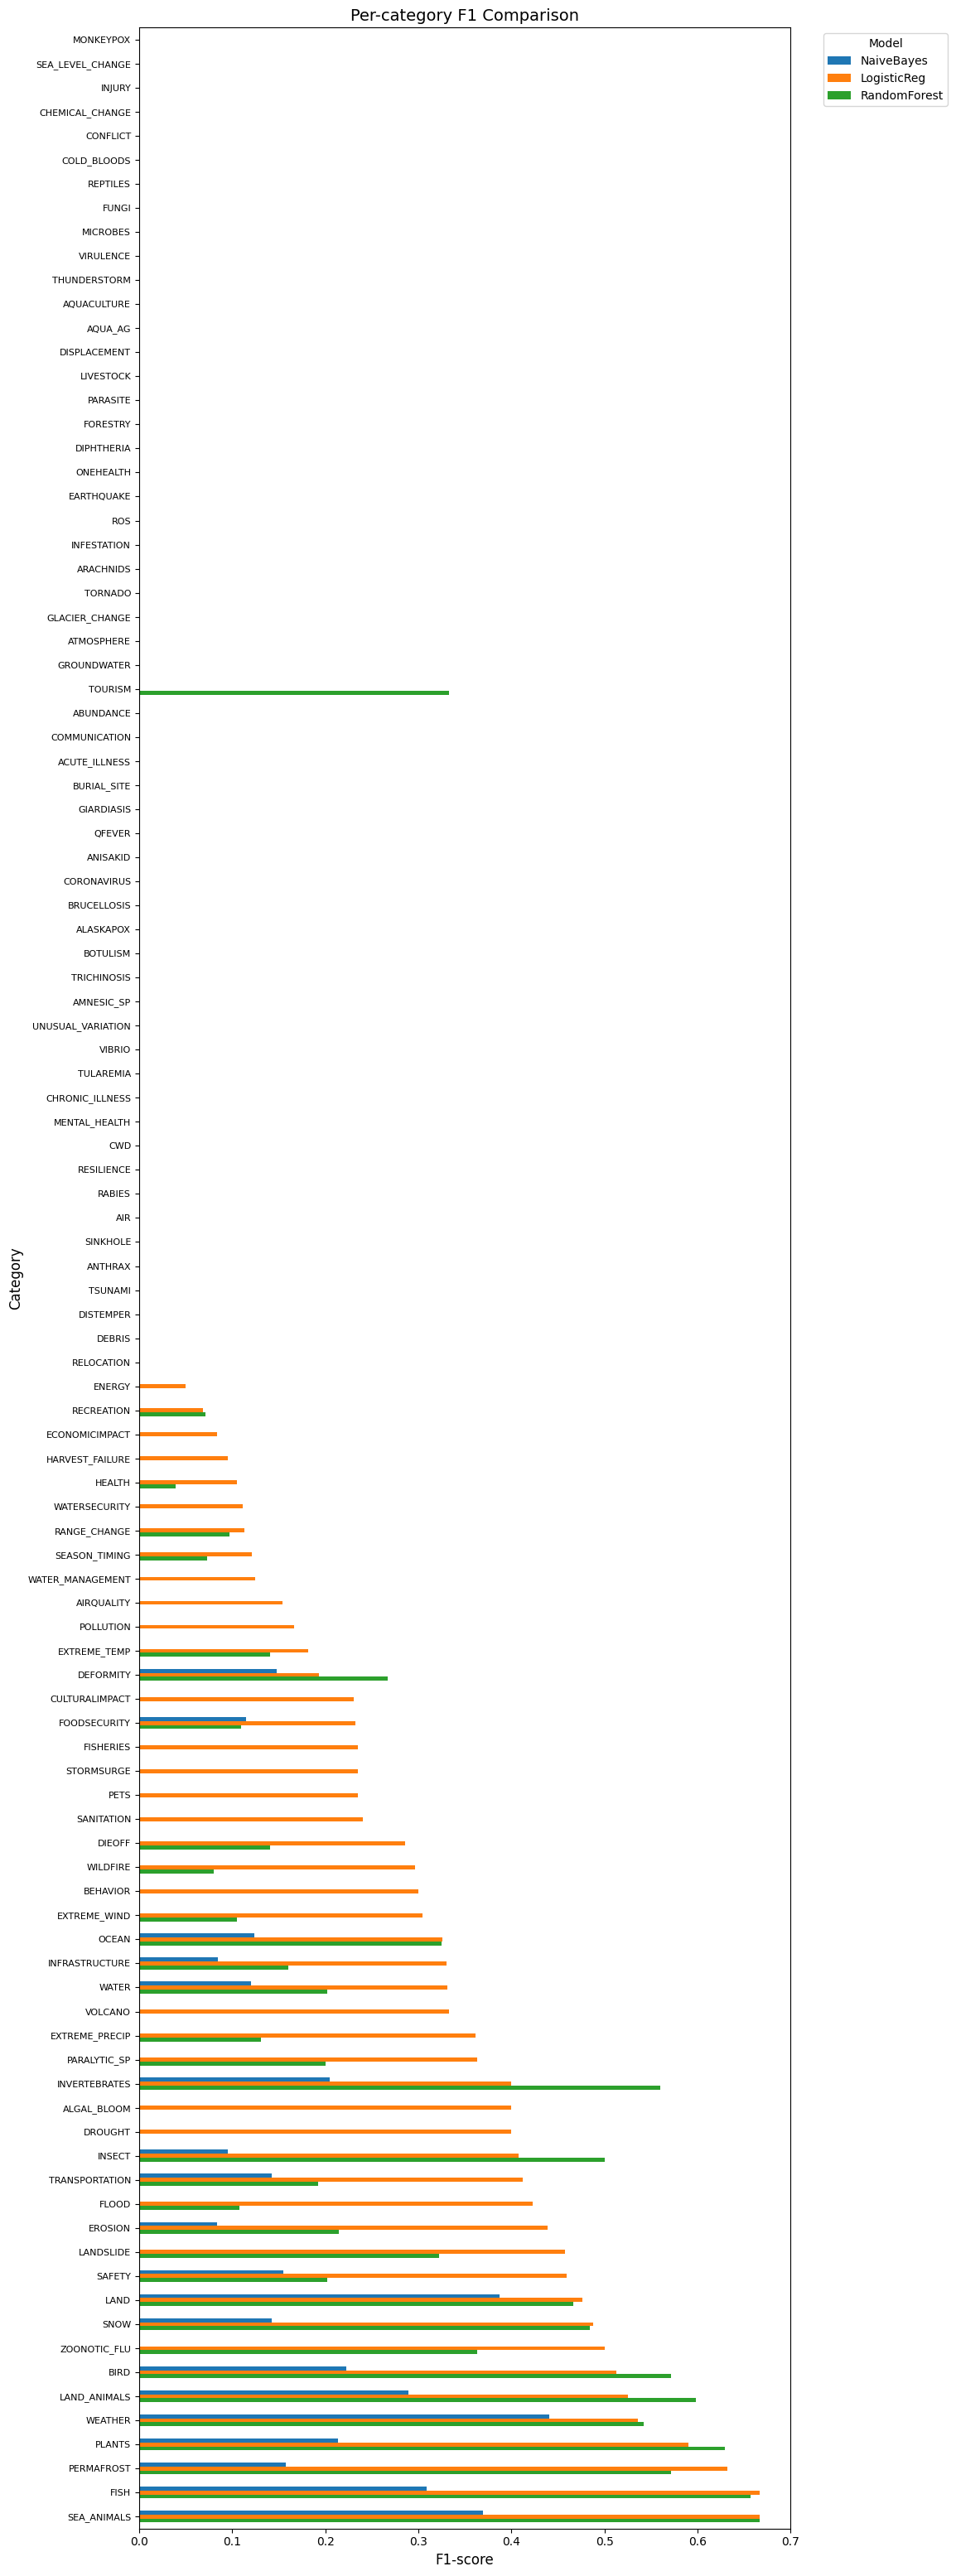

In [67]:
import matplotlib.pyplot as plt

# 1) (Optional) Sort by LogisticReg F1-score for a neat ranking
f1_cmp_sorted = f1_cmp.sort_values(by="LogisticReg", ascending=True)

# 2) Build the plot
fig, ax = plt.subplots(
    figsize=(12, max(6, len(f1_cmp_sorted) * 0.3))  # at least 6" tall, or 0.3" per category
)

f1_cmp_sorted.plot.barh(ax=ax)

# 3) Cosmetic tweaks
ax.set_xlabel("F1-score", fontsize=12)
ax.set_ylabel("Category", fontsize=12)
ax.set_title("Per-category F1 Comparison", fontsize=14)

# shrink the y-tick label font so they don’t overlap
ax.tick_params(axis="y", labelsize=8)

# move the legend outside the plot
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.0), title="Model")

# invert y-axis so the highest F1 is on top
ax.invert_yaxis()

plt.tight_layout()
plt.show()


## Stacked


In [26]:
import pandas as pd
from sklearn.ensemble import StackingClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# --- 0) decide your stop‐words etc. as before ---
# ALL_STOPWORDS = BASE_STOPWORDS ∪ {'alaska','usa'} 

# --- 1) find which labels have ≥2 positives in the TRAIN SET ---
label_counts = y_train.sum(axis=0)
keep_labels = label_counts[label_counts >= 2].index.tolist()
drop_labels = label_counts[label_counts < 2].index.tolist()

print(f"Keeping {len(keep_labels)} labels, dropping {len(drop_labels)} constant/rare labels.")

# 2) subset y_train
y_train_sub = y_train[keep_labels]

# 3) build your stacking pipeline exactly as before
stack_core = StackingClassifier(
    estimators=[
        ("nb", MultinomialNB()),
        ("lr", LogisticRegression(solver="liblinear")),
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42))
    ],
    final_estimator=LogisticRegression(solver="liblinear"),
    cv=3,
    n_jobs=-1,
    passthrough=False
)
stacked = OneVsRestClassifier(stack_core, n_jobs=-1)

pipe_stack = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_df=0.9, min_df=5, ngram_range=(1,2),
        stop_words=list(ALL_STOPWORDS)
    )),
    ("clf", stacked)
])

# 4) fit only on the subset of labels
pipe_stack.fit(X_train, y_train_sub)

# 5) predict
y_pred_sub = pipe_stack.predict(X_test)

# 6) turn into DataFrame so we can re-add dropped labels
y_pred_stack = pd.DataFrame(
    y_pred_sub,
    columns=keep_labels,
    index=X_test.index
)

# 7) add the dropped labels back in as all zeros
for col in drop_labels:
    y_pred_stack[col] = 0

# 8) reorder to original column order
y_pred_stack = y_pred_stack[y_train.columns]

# 9) evaluate
from sklearn.metrics import classification_report
print(classification_report(
    y_test,
    y_pred_stack.values,
    target_names=cat_cols,
    zero_division=0
))


Keeping 98 labels, dropping 6 constant/rare labels.


/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/Users/emine2/Documents/

                   precision    recall  f1-score   support

          WEATHER       0.66      0.55      0.60       124
            OCEAN       0.56      0.22      0.32        85
             LAND       0.60      0.42      0.50        99
           SAFETY       0.70      0.32      0.44       104
            WATER       0.57      0.22      0.32        94
             SNOW       0.68      0.46      0.55       100
           HEALTH       0.00      0.00      0.00        49
   TRANSPORTATION       0.68      0.29      0.40        91
           DIEOFF       0.54      0.26      0.35        58
     EXTREME_TEMP       0.44      0.08      0.13        51
             FISH       0.82      0.62      0.71        82
     LAND_ANIMALS       0.88      0.54      0.67        65
   INFRASTRUCTURE       0.54      0.21      0.30        68
      SEA_ANIMALS       0.91      0.58      0.71        53
           PLANTS       0.82      0.60      0.69        67
     FOODSECURITY       0.69      0.13      0.22       

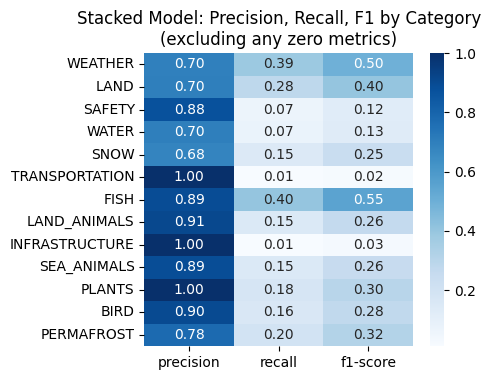

Categories with at least one zero in precision/recall/f1-score (omitted):
- OCEAN
- HEALTH
- DIEOFF
- EXTREME_TEMP
- FOODSECURITY
- RANGE_CHANGE
- SEASON_TIMING
- EXTREME_PRECIP
- ECONOMICIMPACT
- RECREATION
- INVERTEBRATES
- CULTURALIMPACT
- FLOOD
- INSECT
- AIR
- ENERGY
- WILDFIRE
- EXTREME_WIND
- DEFORMITY
- ABUNDANCE
- FISHERIES
- SANITATION
- BEHAVIOR
- EROSION
- LANDSLIDE
- POLLUTION
- WATERSECURITY
- DROUGHT
- MICROBES
- VIRULENCE
- HARVEST_FAILURE
- AIRQUALITY
- PETS
- AQUA_AG
- DISPLACEMENT
- LIVESTOCK
- PARASITE
- ALGAL_BLOOM
- WATER_MANAGEMENT
- ONEHEALTH
- ZOONOTIC_FLU
- ROS
- INFESTATION
- ARACHNIDS
- STORMSURGE
- GLACIER_CHANGE
- ATMOSPHERE
- GROUNDWATER
- TOURISM
- COMMUNICATION
- DEBRIS
- TORNADO
- PARALYTIC_SP
- EARTHQUAKE
- FORESTRY
- AQUACULTURE
- VOLCANO
- THUNDERSTORM
- FUNGI
- REPTILES
- COLD_BLOODS
- CONFLICT
- CHEMICAL_CHANGE
- INJURY
- SEA_LEVEL_CHANGE
- ACUTE_ILLNESS
- MENTAL_HEALTH
- BURIAL_SITE
- RABIES
- SINKHOLE
- ANTHRAX
- RESILIENCE
- DISTEMPER
- RELOCAT

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

# 1) Build the classification report dict for your stacked model
report_stack = classification_report(
    y_test,
    y_pred_stack.values,        # your padded DataFrame’s values
    target_names=cat_cols,
    output_dict=True,
    zero_division=0
)

# 2) Convert to DataFrame and isolate the category rows
report_stack_df = pd.DataFrame(report_stack).transpose()
class_df_stack = report_stack_df.loc[cat_cols]

# 3) Identify metrics and mask out any category having a zero
metrics = ["precision", "recall", "f1-score"]
mask_nonzero_all = (class_df_stack[metrics] > 0).all(axis=1)

nonzero_all_stack = class_df_stack[mask_nonzero_all]
zero_any_stack    = class_df_stack[~mask_nonzero_all].index.tolist()

# 4) Plot heatmap for non-zero-only categories
plt.figure(figsize=(5, len(nonzero_all_stack) * 0.3))
sns.heatmap(
    nonzero_all_stack[metrics],
    annot=True,
    fmt=".2f",
    cmap="Blues"
)
plt.title(
    "Stacked Model: Precision, Recall, F1 by Category\n"
    "(excluding any zero metrics)"
)
plt.tight_layout()
plt.show()

# 5) List the omitted categories
print("Categories with at least one zero in precision/recall/f1-score (omitted):")
for cat in zero_any_stack:
    print("-", cat)


In [38]:
# --- 1) Build DataFrame for stacked‐model predictions ---
# If y_pred_stack is a NumPy array, wrap it in DataFrame first:
# y_pred_stack_df = pd.DataFrame(y_pred_stack, columns=cat_cols, index=X_test.index)
# But if you already created y_pred_stack as a DataFrame, just rename:
y_pred_stack_df = y_pred_stack.copy()

# 2) Boolean masks for “exact match” vs. misclassified
mask_correct_stack   = (y_test_df.values == y_pred_stack_df.values).all(axis=1)
mask_incorrect_stack = ~mask_correct_stack

# 3) Pick one example of each
idx_corr_stack = X_test[mask_correct_stack].index[10]
idx_inc_stack  = X_test[mask_incorrect_stack].index[10]

# 4) Helper to list the active categories
def labels_of(row):
    return row[row == 1].index.tolist()

# 5) Display a correctly and an incorrectly classified post
print("=== Stacked Model: Correctly Classified ===")
print("Text:            ", X_test.loc[idx_corr_stack])
print("True labels:     ", labels_of(y_test_df.loc[idx_corr_stack]))
print("Predicted labels:", labels_of(y_pred_stack_df.loc[idx_corr_stack]))
print()

print("=== Stacked Model: Misclassified ===")
print("Text:            ", X_test.loc[idx_inc_stack])
print("True labels:     ", labels_of(y_test_df.loc[idx_inc_stack]))
print("Predicted labels:", labels_of(y_pred_stack_df.loc[idx_inc_stack]))


=== Stacked Model: Correctly Classified ===
Text:             Fish had a brownish moldy growth all over its body.
True labels:      ['FISH']
Predicted labels: ['FISH']

=== Stacked Model: Misclassified ===
Text:             Alaska's largest sockeye salmon run exceeded expectations in numbers but featured the smallest fish on record, posing challenges for commercial harvest.
True labels:      ['FISH', 'ABUNDANCE', 'FISHERIES', 'HARVEST_FAILURE']
Predicted labels: ['FISH']


In [43]:
import matplotlib.pyplot as plt
import pandas as pd

# --- 0) Ensure you have these from before ---
# get_f1_series
# f1_nb, f1_lr, f1_rf
# y_pred_stack (DataFrame or array of your stacked model predictions)

# 1) Compute the Stacked model’s per-category F1
f1_stacked = get_f1_series(y_test, y_pred_stack.values).rename("Stacked")

# 2) Combine all four into one DataFrame
f1_cmp_all = pd.concat([f1_nb, f1_lr, f1_rf, f1_stacked], axis=1)

# 3) (Optional) Sort by your favorite column, e.g. LogisticReg
f1_cmp_sorted = f1_cmp_all.sort_values(by="LogisticReg", ascending=True)

# 4) Plot
fig, ax = plt.subplots(
    figsize=(12, max(6, len(f1_cmp_sorted) * 0.3))
)
f1_cmp_sorted.plot.barh(ax=ax)

# 5) Cosmetic tweaks
ax.set_xlabel("F1-score", fontsize=12)
ax.set_ylabel("Category", fontsize=12)
ax.set_title("Per-category F1 Comparison (including Stacked)", fontsize=14)
ax.tick_params(axis="y", labelsize=8)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.0), title="Model")
ax.invert_yaxis()

plt.tight_layout()
plt.show()


NameError: name 'get_f1_series' is not defined

# stacked with different parameters?

In [31]:
import numpy as np
import pandas as pd

from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.multiclass import OneVsRestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

# --- 0) assume X_train, X_test, y_train, y_test, cat_cols, ALL_STOPWORDS are already in scope ---

# 1) Identify and drop ultra-rare labels (fewer than cv folds positives)
cv_folds = 3
label_counts = y_train.sum(axis=0)
keep_labels = label_counts[label_counts >= cv_folds].index.tolist()
drop_labels = label_counts[label_counts <  cv_folds].index.tolist()

print(f"Keeping {len(keep_labels)} labels, dropping {len(drop_labels)} too-rare labels.")

# 2) Subset y_train to only “keep” labels
y_train_sub = y_train[keep_labels]

# 3) Build stacking core and wrap in OneVsRest
stack_core = StackingClassifier(
    estimators=[
        ("nb", MultinomialNB(alpha=0.5)),
        ("lr", LogisticRegression(C=1.0, class_weight="balanced", solver="liblinear")),
        ("rf", RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", random_state=42))
    ],
    final_estimator=LogisticRegression(C=1.0, solver="liblinear"),
    stack_method="predict_proba",
    passthrough=True,
    cv=cv_folds,
    n_jobs=-1
)
wrapped = OneVsRestClassifier(stack_core, n_jobs=-1)

# 4) Full pipeline: TF–IDF → OneVsRest(stack)
pipe = Pipeline([
    ("vect", TfidfVectorizer(
        stop_words=list(ALL_STOPWORDS),
        ngram_range=(1,3),
        max_df=0.8,
        min_df=3,
        analyzer="char_wb"
    )),
    ("clf", wrapped)
])

# 5) Grid-search only over the final‐estimator C
param_grid = {
    "clf__estimator__final_estimator__C": [0.1, 1, 10]
}

grid = GridSearchCV(
    pipe,
    param_grid,
    cv=3,
    n_jobs=-1,
    verbose=2,
    scoring="f1_micro"    # or "f1_macro"
)
grid.fit(X_train, y_train_sub)

print("Best params:", grid.best_params_)

# 6) Predict on the subset of labels
y_pred_sub = grid.predict(X_test)

# 7) Pad back the dropped labels as all zeros
y_pred_stack = pd.DataFrame(
    y_pred_sub,
    index=X_test.index,
    columns=keep_labels
)
for col in drop_labels:
    y_pred_stack[col] = 0

# 8) Reorder columns to original cat_cols
y_pred_stack = y_pred_stack[cat_cols]

# 9) Final evaluation
print(classification_report(
    y_test.values,
    y_pred_stack.values,
    target_names=cat_cols,
    zero_division=0
))


Keeping 91 labels, dropping 13 too-rare labels.
Fitting 3 folds for each of 3 candidates, totalling 9 fits


/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/feature_extraction/text.py:539: UserWarning: The parameter 'stop_words' will not be used since 'analyzer' != 'word'
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/feature_extraction/text.py:539: UserWarning: The parameter 'stop_words' will not be used since 'analyzer' != 'word'
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/feature_extraction/text.py:539: UserWarning: The parameter 'stop_words' will not be used since 'analyzer' != 'word'
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/feature_extraction/text.py:539: UserWarning: The parameter 'stop_words' will not be used since 'analyzer' != 'word'
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577

[CV] END ...............clf__estimator__final_estimator__C=1; total time=12.8min


/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_validation.py:1380: RuntimeWarning: Number of classes in training fold (1) does not match total number of classes (2). Results may not be appropriate for your use case. To fix this, use a cross-validation technique resulting in properly stratified folds
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/feature_extraction/tex

[CV] END .............clf__estimator__final_estimator__C=0.1; total time=12.9min


/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


... (7 outputs left out)

/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/Users/emine2/Documents/

[CV] END ..............clf__estimator__final_estimator__C=10; total time= 3.6min


/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
6 fits failed out of a total of 9.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
6 fits failed with the following error:
joblib.externals.loky.process_executor._RemoteTraceback: 
"""
Traceback (most recent call last):
  File "/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/joblib/_utils.py", line 72

Best params: {'clf__estimator__final_estimator__C': 0.1}
                   precision    recall  f1-score   support

          WEATHER       0.70      0.39      0.50       124
            OCEAN       0.00      0.00      0.00        85
             LAND       0.70      0.28      0.40        99
           SAFETY       0.88      0.07      0.12       104
            WATER       0.70      0.07      0.13        94
             SNOW       0.68      0.15      0.25       100
           HEALTH       0.00      0.00      0.00        49
   TRANSPORTATION       1.00      0.01      0.02        91
           DIEOFF       0.00      0.00      0.00        58
     EXTREME_TEMP       0.00      0.00      0.00        51
             FISH       0.89      0.40      0.55        82
     LAND_ANIMALS       0.91      0.15      0.26        65
   INFRASTRUCTURE       1.00      0.01      0.03        68
      SEA_ANIMALS       0.89      0.15      0.26        53
           PLANTS       1.00      0.18      0.30        6